In [2]:
from sae import load_sdxl_turbo_sae
from huggingface_hub import hf_hub_download
import torch
from PIL import Image

In [3]:
file_path = hf_hub_download(
    repo_id=f"Goodfire/SDXL-Turbo-SAE-ldown.attns.2.1",
    filename=f"SDXL-Turbo-SAE-ldown_blocks.2.attentions.1.pt",
    repo_type="model"
)
device = "cpu"
sae = load_sdxl_turbo_sae(file_path, device, dtype=torch.float32,)
sae.eval()

BatchTopKSAE(
  (encoder): Linear(in_features=1280, out_features=10240, bias=True)
  (decoder): Linear(in_features=10240, out_features=1280, bias=True)
)

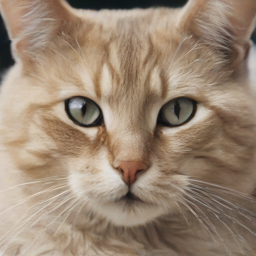

Top 10 feature indices with highest total activation and their sums:
Feature index: 1236, Total activation: 3723.3164
Feature index: 8004, Total activation: 3582.5276
Feature index: 3149, Total activation: 3319.9287
Feature index: 8392, Total activation: 2995.7651
Feature index: 1573, Total activation: 2975.4397
Feature index: 2824, Total activation: 1858.3892
Feature index: 3357, Total activation: 1478.2888
Feature index: 1500, Total activation: 1313.8911
Feature index: 6661, Total activation: 1259.5693
Feature index: 1935, Total activation: 1229.2742


In [8]:
acts = torch.load('./example_activations.pt', map_location='cpu', weights_only=True)
image = Image.open('./example_img.png')
image.resize((256, 256)).show()

features = sae.encode(acts.to(torch.float32))  # 256 x 10240 for features in each patch

# Get the top 10 features by summing activations across all patches
top10_features = torch.topk(features.sum(dim=0), 10)
top10_indices, top10_values = top10_features.indices.tolist(), top10_features.values.tolist()

print("Top 10 feature indices with highest total activation and their sums:")
for idx, val in zip(top10_indices, top10_values):
    print(f"Feature index: {idx}, Total activation: {val:.4f}")